PatchTST on Wind Power Generation data (Kaggle) — multi-horizon, full-data vs low-data comparison.

1. Install dependencies

In [2]:
!pip install -q neuralforecast pandas numpy scikit-learn

In [3]:
import glob
import os
import time
import numpy as np
import pandas as pd
import torch
from neuralforecast import NeuralForecast
from neuralforecast.models import PatchTST
from neuralforecast.losses.pytorch import MSE

2. Configuration

In [4]:
DATA_DIR = "/content/Dataset"
HORIZONS = [24, 48, 96, 192, 336]         # forecast horizons to sweep (in number of time steps)
TRAIN_FRACS = [1.0, 0.10]                 # full data vs 10% low-data setting
INPUT_LEN = 512                           # lookback window (reduce if a series is short)
MAX_STEPS = 500
TEST_FRAC = 0.20                          # last 20% of each series held out as test
EVAL_MAX_WINDOWS_PER_SERIES = 20          # cap rolling-eval windows per file/turbine so evaluation
                                           # cost stays bounded regardless of how long/dense a series is;
                                           # windows are sampled evenly across the test period.
                                           # Lower this (e.g. 10) for an even faster first run.
RANDOM_SEED = 42
RESULTS_CSV = "results_patchtst_wind.csv"


DATETIME_HINTS = ["date/time", "date_time", "datetime", "timestamp", "date", "time"]
TARGET_HINTS = [
    "lv activepower", "active power", "activepower", "power (kw)", "power(kw)",
    "power output", "generated power", "wind power", "power",
]

TARGET_EXCLUDE_HINTS = ["theoretical", "curve"]

MANUAL_OVERRIDES = {}

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)


3. Auto-detect datetime + target column, load, and combine all CSVs

In [5]:
def find_column(columns, hints, exclude_hints=None):
    cols_lower = {c: c.lower() for c in columns}
    exclude_hints = exclude_hints or []
    # exact/substring match against hints, in priority order
    for hint in hints:
        for c, cl in cols_lower.items():
            if hint in cl and not any(ex in cl for ex in exclude_hints):
                return c
    return None


def load_one_csv(path):
    fname = os.path.basename(path)
    df = pd.read_csv(path)

    override = MANUAL_OVERRIDES.get(fname, {})
    dt_col = override.get("datetime") or find_column(df.columns, DATETIME_HINTS)
    target_col = override.get("target") or find_column(
        df.columns, TARGET_HINTS, exclude_hints=TARGET_EXCLUDE_HINTS
    )

    if dt_col is None or target_col is None:
        print(f"  [SKIP] {fname}: could not auto-detect columns "
              f"(datetime={dt_col}, target={target_col}). "
              f"Add an entry to MANUAL_OVERRIDES for this file.")
        return None

    print(f"  [OK]   {fname}: datetime_col='{dt_col}', target_col='{target_col}'")

    out = pd.DataFrame()
    out["ds"] = pd.to_datetime(df[dt_col], errors="coerce", dayfirst=True)
    out["y"] = pd.to_numeric(df[target_col], errors="coerce")
    out["unique_id"] = os.path.splitext(fname)[0]
    out = out.dropna(subset=["ds", "y"]).sort_values("ds")
    out = out.drop_duplicates(subset=["ds"])
    return out.reset_index(drop=True)


csv_paths = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")))
if not csv_paths:
    raise FileNotFoundError(
        f"No .csv files found in {DATA_DIR}. Check the folder name/path in Colab "
        f"(left sidebar 'Files' panel) and update DATA_DIR if needed."
    )

print(f"Found {len(csv_paths)} CSV file(s) in {DATA_DIR}:")
frames = [load_one_csv(p) for p in csv_paths]
frames = [f for f in frames if f is not None and len(f) > (INPUT_LEN + max(HORIZONS) + 10)]

if not frames:
    raise ValueError(
        "No usable series after loading. Either column auto-detection failed for "
        "all files (check MANUAL_OVERRIDES) or every series is too short for "
        "INPUT_LEN + max(HORIZONS)."
    )

df = pd.concat(frames, ignore_index=True)
print(f"\nLoaded {df.unique_id.nunique()} series, {len(df)} total rows.")
print(df.groupby("unique_id").agg(n_rows=("y", "size"),
                                   start=("ds", "min"),
                                   end=("ds", "max")))

Found 4 CSV file(s) in /content/Dataset:
  [OK]   Location1.csv: datetime_col='Time', target_col='Power'
  [OK]   Location2.csv: datetime_col='Time', target_col='Power'
  [OK]   Location3.csv: datetime_col='Time', target_col='Power'
  [OK]   Location4.csv: datetime_col='Time', target_col='Power'

Loaded 4 series, 69024 total rows.
           n_rows      start                 end
unique_id                                       
Location1   17256 2017-01-02 2021-12-12 23:00:00
Location2   17256 2017-01-02 2021-12-12 23:00:00
Location3   17256 2017-01-02 2021-12-12 23:00:00
Location4   17256 2017-01-02 2021-12-12 23:00:00


4. Infer sampling frequency (many wind datasets are 10-min, not hourly)

In [6]:
def infer_freq(df):
    one_series = df[df.unique_id == df.unique_id.iloc[0]].sort_values("ds")
    diffs = one_series["ds"].diff().dropna()
    if diffs.empty:
        return "H"
    common_diff = diffs.mode().iloc[0]
    try:
        return pd.tseries.frequencies.to_offset(common_diff).freqstr
    except Exception:
        return "H"


FREQ = infer_freq(df)
print(f"\nInferred sampling frequency: {FREQ}")


Inferred sampling frequency: h


5. Build train/test splits per series (test = last TEST_FRAC of each series)

In [7]:
def make_series_splits(df, horizon, train_frac):
    """
    For each unique_id, holds out the last TEST_FRAC of the series as test.
    train_frac controls how much of the remaining training region is used
    (most recent chunk of it), to simulate the low-data setting.
    Returns: train_df (all series concatenated), and a dict of
    {unique_id: test_context_df} where test_context_df includes the
    INPUT_LEN lookback + the held-out test region, for rolling evaluation.
    """
    train_parts = []
    test_contexts = {}

    for uid, g in df.groupby("unique_id"):
        g = g.sort_values("ds").reset_index(drop=True)
        n = len(g)
        n_test = max(int(n * TEST_FRAC), horizon + 10)
        n_train_full = n - n_test
        if n_train_full < INPUT_LEN + horizon + 10:
            continue  # too short for this horizon, skip this series for this run

        n_train = max(int(n_train_full * train_frac), INPUT_LEN + horizon + 10)
        n_train = min(n_train, n_train_full)

        train_g = g.iloc[n_train_full - n_train: n_train_full]
        test_ctx_g = g.iloc[max(n_train_full - INPUT_LEN, 0):]

        train_parts.append(train_g)
        test_contexts[uid] = test_ctx_g

    if not train_parts:
        return None, None
    train_df = pd.concat(train_parts, ignore_index=True)
    return train_df, test_contexts

6. Train + evaluate PatchTST jointly across all series for one (horizon, train_frac)

In [8]:
def run_one(df, horizon, train_frac):
    train_df, test_contexts = make_series_splits(df, horizon, train_frac)
    if train_df is None:
        print(f"  [SKIP] horizon={horizon}: no series long enough.")
        return None

    model = PatchTST(
        h=horizon,
        input_size=INPUT_LEN,
        patch_len=16,
        stride=8,
        max_steps=MAX_STEPS,
        loss=MSE(),
        scaler_type="standard",
        random_seed=RANDOM_SEED,
    )
    nf = NeuralForecast(models=[model], freq=FREQ)

    # ---- train (one joint/global model across all series) ----
    t0 = time.time()
    nf.fit(df=train_df)
    train_time_sec = time.time() - t0

    # ---- rolling-window evaluation, BATCHED into one predict() call ----

    step = horizon  # non-overlapping windows; shrink for denser eval
    window_ctx_parts = []
    window_meta = []  # (synthetic_uid, true_future_values)

    for uid, ctx_full in test_contexts.items():
        ctx_full = ctx_full.reset_index(drop=True)
        n_windows = max((len(ctx_full) - INPUT_LEN - horizon) // step + 1, 0)
        # Cap windows per series so evaluation cost doesn't scale unbounded
        # with very long/dense series; sample evenly across the test period.
        if n_windows > EVAL_MAX_WINDOWS_PER_SERIES:
            chosen = np.linspace(0, n_windows - 1, EVAL_MAX_WINDOWS_PER_SERIES).astype(int)
            chosen = sorted(set(chosen.tolist()))
        else:
            chosen = list(range(n_windows))

        for w in chosen:
            start = INPUT_LEN + w * step
            ctx = ctx_full.iloc[start - INPUT_LEN:start].copy()
            true_future = ctx_full.iloc[start:start + horizon]
            if len(true_future) < horizon or len(ctx) < INPUT_LEN:
                continue

            synthetic_uid = f"{uid}__w{w}"
            ctx["unique_id"] = synthetic_uid
            window_ctx_parts.append(ctx)
            window_meta.append((synthetic_uid, true_future["y"].values))

    if not window_ctx_parts:
        print(f"  [SKIP] horizon={horizon}, train_frac={train_frac}: "
              f"no evaluable windows (series too short relative to horizon).")
        return None

    batch_ctx_df = pd.concat(window_ctx_parts, ignore_index=True)
    n_forecasts = len(window_meta)

    print(f"    Running {n_forecasts} forecasts in a single batched predict() call...")
    t1 = time.time()
    fcst = nf.predict(df=batch_ctx_df)
    total_predict_sec = time.time() - t1

    avg_latency_ms = (total_predict_sec / n_forecasts) * 1000

    fcst_by_uid = fcst.set_index("unique_id")["PatchTST"]
    preds_all, actuals_all = [], []
    for synthetic_uid, true_future_vals in window_meta:
        preds_all.append(fcst_by_uid.loc[synthetic_uid].values[:horizon]
                          if hasattr(fcst_by_uid.loc[synthetic_uid], "values")
                          else np.array([fcst_by_uid.loc[synthetic_uid]]))
        actuals_all.append(true_future_vals)

    preds_all = np.concatenate(preds_all)
    actuals_all = np.concatenate(actuals_all)

    mse = float(np.mean((preds_all - actuals_all) ** 2))
    mae = float(np.mean(np.abs(preds_all - actuals_all)))
    n_params = sum(p.numel() for p in model.state_dict().values())

    return {
        "horizon": horizon,
        "train_frac": train_frac,
        "mse": mse,
        "mae": mae,
        "train_time_sec": round(train_time_sec, 2),
        "inference_latency_ms": round(avg_latency_ms, 2),
        "n_params": n_params,
        "n_series_used": len(test_contexts),
    }

Output: results_patchtst_wind.csv with columns horizon, train_frac, mse, mae, train_time_sec, inference_latency_ms, n_params, n_series_used

7. Sweep all (horizon, train_frac) combinations

In [9]:
results = []
for h in HORIZONS:
    for frac in TRAIN_FRACS:
        print(f"\n=== Horizon={h}, train_frac={frac} ===")
        res = run_one(df, h, frac)
        if res is not None:
            print(res)
            results.append(res)

results_df = pd.DataFrame(results)
results_df.to_csv(RESULTS_CSV, index=False)
print(f"\nSaved results to {RESULTS_CSV}")
print(results_df)

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores



=== Horizon=24, train_frac=1.0 ===


INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.callbacks.model_summary:
  | Name                | Type              | Params | Mode 
------------------------------------------------------------------
0 | loss                | MSE               | 0      | train
1 | hist_cat_embeddings | ModuleList        | 0      | train
2 | futr_cat_embeddings | ModuleList        | 0      | train
3 | stat_cat_embeddings | ModuleList        | 0      | train
4 | padder_train        | ConstantPad1d     | 0      | train
5 | scaler              | TemporalNorm      | 0      | train
6 | model               | PatchTST_backbone | 604 K  | train
------------------------------------------------------------------
604 K     Trainable params
3         Non-trainable params
604 K     Total params
2.418     Total estimated model params size (MB)
93        Modules in train mode
0         Modules in eval mode


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (135 outputs left out)

    Running 40 forecasts in a single batched predict() call...


/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Predicting: |          | 0/? [00:00<?, ?it/s]

{'horizon': 336, 'train_frac': 0.1, 'mse': 0.09404266356882363, 'mae': 0.2397692367119502, 'train_time_sec': 102.03, 'inference_latency_ms': 4.24, 'n_params': 3162201, 'n_series_used': 4}

Saved results to results_patchtst_wind.csv
   horizon  train_frac       mse       mae  train_time_sec  \
0       24         1.0  0.043441  0.158324          100.71   
1       24         0.1  0.069691  0.195733           99.77   
2       48         1.0  0.050566  0.177934          100.98   
3       48         0.1  0.080479  0.213332          100.30   
4       96         1.0  0.052129  0.179816          101.62   
5       96         0.1  0.084173  0.224343          101.01   
6      192         1.0  0.048608  0.173194          101.88   
7      192         0.1  0.082906  0.224570          101.65   
8      336         1.0  0.048854  0.173355          103.17   
9      336         0.1  0.094043  0.239769          102.03   

   inference_latency_ms  n_params  n_series_used  
0                  2.16    605985 

MSE vs Horizon, full data vs low data

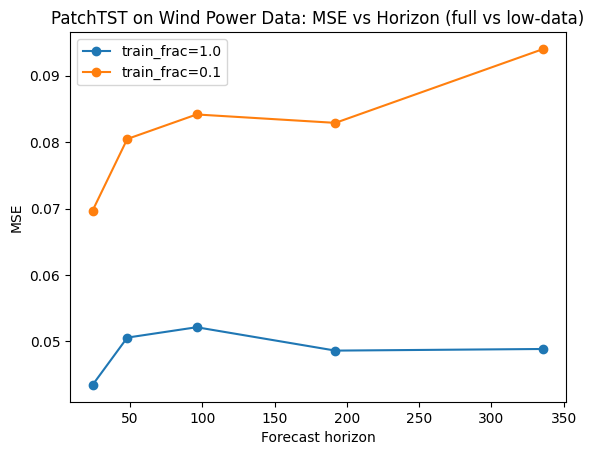

In [10]:
import matplotlib.pyplot as plt

for frac in TRAIN_FRACS:
    sub = results_df[results_df.train_frac == frac].sort_values("horizon")
    if len(sub):
        plt.plot(sub.horizon, sub.mse, marker="o", label=f"train_frac={frac}")
plt.xlabel("Forecast horizon")
plt.ylabel("MSE")
plt.title("PatchTST on Wind Power Data: MSE vs Horizon (full vs low-data)")
plt.legend()
plt.show()